# Part 1: Discrete Local Search

I have implemented a modified hill climber algorithm, and a standard hill climber algorithm to compare performance and justify design choices.

In [186]:
from workload_data_loader import load_workload_instance

workload_28 = load_workload_instance("multi_resource_n28_m2.txt")
print(f"n = {workload_28[0]}")
print(f"m = {workload_28[1]}")
print(f"Utilities shape = {workload_28[2].shape}")
print(f"Demands shape = {workload_28[3].shape}")
print(f"Capacities shape = {workload_28[4].shape}")
print(f"Unconstrained maximum score = ", sum(workload_28[2]))

n = 28
m = 2
Utilities shape = (28,)
Demands shape = (2, 28)
Capacities shape = (2,)
Unconstrained maximum score =  164045.0


In [187]:
import numpy as np

# Explicit accessors for the workload data structure
def get_options(workload):
    return workload[0]

def get_resources(workload):
    return workload[1]

def get_utilities(workload):
    return workload[2]

def get_demands(workload):
    return workload[3]

def get_capacities(workload):
    return workload[4]

# Evaluates a given solution (an (n,1) vector) on a workload.
# Returns a boolean for solution validity, constrained utility (zero if resource limits exceeded), 
# unconstrained utility (utility if there were no resource limits), and resource usages
def evaluate(workload, solution):
    usage = np.dot(get_demands(workload), solution)
    utility = np.dot(get_utilities(workload), solution)
    valid_solution = not any([d > c for (d, c) in zip(usage, get_capacities(workload))])

    return valid_solution, utility if valid_solution else 0, utility, usage

print("----- Evaluation function -----")
print()
print("All zeros (guaranteed valid)  :", evaluate(workload_28, np.zeros(28)))
print("All ones (guaranteed invalid) :", evaluate(workload_28, np.ones(28)))

----- Evaluation function -----

All zeros (guaranteed valid)  : (True, np.float64(0.0), np.float64(0.0), array([0., 0.]))
All ones (guaranteed invalid) : (False, 0, np.float64(164045.0), array([1125.,  995.]))


In [188]:
# Returns a random solution for the provided workload
def random_solution(workload, prop0 = 0.5):
    return np.random.choice([0, 1], get_options(workload), True, [prop0, 1 - prop0])

# Returns a directly adjactent neighbour of the provided solution. Flips one bit.
def neighbour(solution):
    idx = np.random.randint(0, len(solution))

    new_solution = np.copy(solution)
    new_solution[idx] = 0 if new_solution[idx] == 1 else 1

    return new_solution

demo_random_sol = random_solution(workload_28)
demo_neighbour = neighbour(demo_random_sol)
print("----- Neighbour function -----")
print()
print("initial random       :", demo_random_sol)
print("neighbour            :", demo_neighbour)
print()
print("absolute difference  :", np.abs(demo_random_sol - demo_neighbour))

----- Neighbour function -----

initial random       : [1 0 1 0 1 0 0 0 1 0 1 1 1 1 1 1 0 0 1 1 1 1 1 1 0 1 0 0]
neighbour            : [1 0 0 0 1 0 0 0 1 0 1 1 1 1 1 1 0 0 1 1 1 1 1 1 0 1 0 0]

absolute difference  : [0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [189]:

# Returns the overall resource usage percentage, weighting all resources equally.
# Converts the usage vector to percentages, calculates the length of this vector, then normalises again
def norm_usage(workload, usage):
    return np.linalg.norm(usage / get_capacities(workload)) / np.linalg.norm(np.ones(len(usage)))

# Very standard hill climber algorithm.
def hill_climb_base(workload, n):
    trace = []
    best_sol = random_solution(workload, 0.9)
    best_eval = evaluate(workload, best_sol)
    trace.append(best_eval[1])

    for _ in range(n):
        neig = neighbour(best_sol)
        neig_eval = evaluate(workload, neig)
        if neig_eval[1] >= best_eval[1]:
            best_sol = neig
            best_eval = neig_eval

        trace.append(best_eval[1])

    return best_sol, best_eval, trace


# Applies n mutations by recursively calling the neighbour function
def recursive_neighbour(solution, n = 0):
    if n <= 0:
        return solution
    else:
        return recursive_neighbour(neighbour(solution), n - 1)

# Modified hill climber algorithm.
# Each time the algorithm lands on a worse solution after mutation, the algorithm will increase the 
# number of applied mutations for the next iteration. This should encourage more vigorous exploration
# when stuck in small local minima. Logarithmic scaling was found to perform better than linear scaling.
def hill_climb_modified(workload, n):
    trace = []
    best_sol = random_solution(workload, 0.9)
    best_eval = evaluate(workload, best_sol)
    n_failures = 0
    trace.append(best_eval[1])

    for _ in range(n):
        neig = recursive_neighbour(best_sol, np.log2(n_failures + 1) + 1)
        neig_eval = evaluate(workload, neig)
        if neig_eval[1] >= best_eval[1]:
            best_sol = neig
            best_eval = neig_eval
            n_failures = 0
        else:
            n_failures += 1

        trace.append(best_eval[1])

    return best_sol, best_eval, trace

In [190]:
import time

np.random.seed(42)

PART_1_RUNS = 1000
PART_1_ITERATIONS = 250

# Performs {n_runs} runs of the function {runner}. Stores the return value of each call, and the time it took to call
# Returns a list of return values and a list of runtimes
def timed_runs(n_runs, runner):
    runs = []
    times = []
    for _ in range(n_runs):
        t1 = time.time()
        runs.append(runner())
        t2 = time.time()
        times.append(t2 - t1)

    return runs, times
        

runs_base, times_base = timed_runs(PART_1_RUNS, lambda: hill_climb_base(workload_28, PART_1_ITERATIONS))
runs_modified, times_modified = timed_runs(PART_1_RUNS, lambda: hill_climb_modified(workload_28, PART_1_ITERATIONS))

traces_base = [run[2] for run in runs_base]
traces_modified = [run[2] for run in runs_modified]

best_base = [run[1][1] for run in runs_base]
best_modified = [run[1][1] for run in runs_modified]

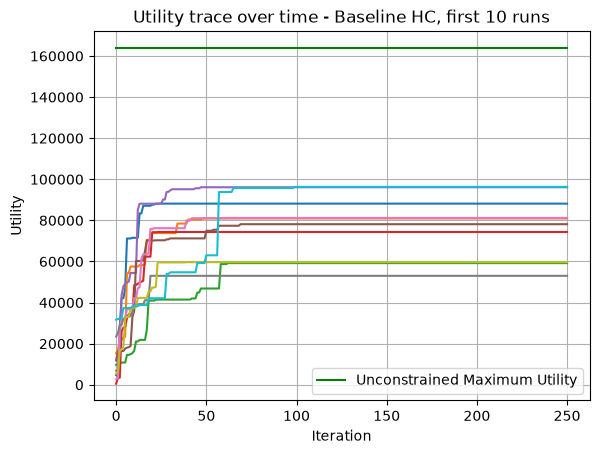

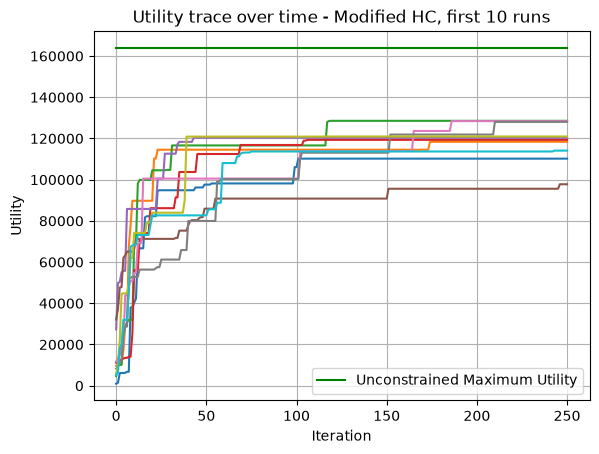

In [191]:
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

unconstrained_max = sum(get_utilities(workload_28))

for trace in traces_base[0:10]:
    plt.plot(trace)

plt.plot([unconstrained_max] * (PART_1_ITERATIONS + 1), color="green", label="Unconstrained Maximum Utility")

plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.title("Utility trace over time - Baseline HC, first 10 runs")
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


for trace in traces_modified[0:10]:
    plt.plot(trace)
    
plt.plot([unconstrained_max] * (PART_1_ITERATIONS + 1), color="green", label="Unconstrained Maximum Utility")

plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.title("Utility trace over time - Modified HC, first 10 runs")
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

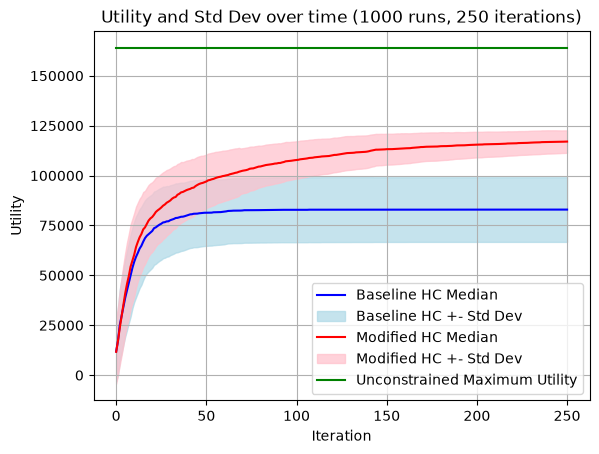

In [192]:
%matplotlib inline

base_median = np.median(traces_base, axis=0)
modified_median = np.median(traces_modified, axis=0)

base_std = np.std(traces_base, axis=0)
modified_std = np.std(traces_modified, axis=0)


plt.plot(base_median, color="blue", label="Baseline HC Median")
plt.fill_between(range(PART_1_ITERATIONS + 1), base_median - base_std, base_median + base_std, color="lightblue", alpha=0.7, label="Baseline HC +- Std Dev")

plt.plot(modified_median, color="red", label="Modified HC Median")
plt.fill_between(range(PART_1_ITERATIONS + 1), modified_median - modified_std, modified_median + modified_std, color="pink", alpha=0.7, label="Modified HC +- Std Dev")

unconstrained_max = sum(get_utilities(workload_28))
plt.plot([unconstrained_max] * (PART_1_ITERATIONS + 1), color="green", label="Unconstrained Maximum Utility")

plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.title(f"Utility and Std Dev over time ({PART_1_RUNS} runs, {PART_1_ITERATIONS} iterations)")
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

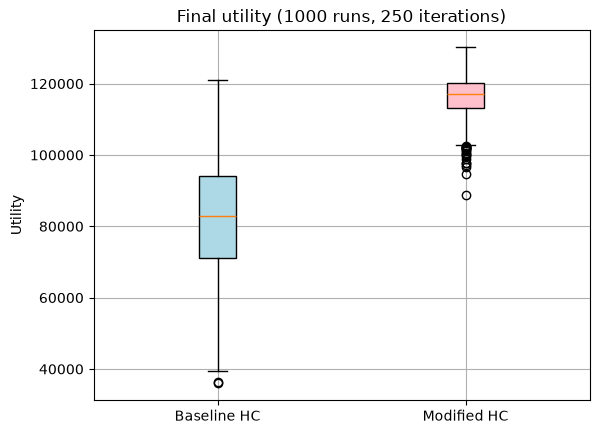

In [193]:
%matplotlib inline

bplot = plt.boxplot([best_base, best_modified], patch_artist=True, tick_labels=['Baseline HC', 'Modified HC'])
for patch, colour in zip(bplot["boxes"], ["lightblue", "pink"]):
    patch.set_facecolor(colour)

plt.title(f"Final utility ({PART_1_RUNS} runs, {PART_1_ITERATIONS} iterations)")
plt.ylabel("Utility")
plt.grid(True)
plt.show()

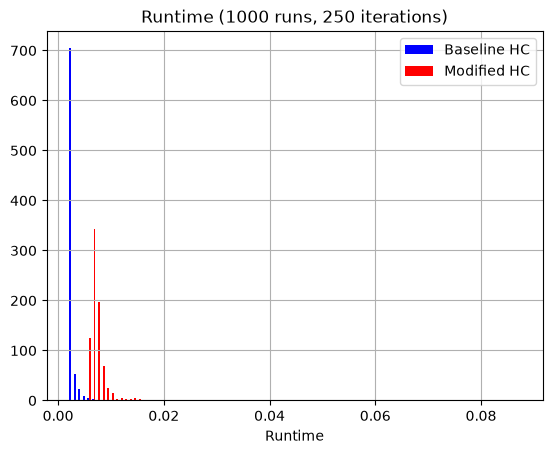

In [194]:
%matplotlib inline

# The outer 200 values were excluded from both datasets to remove outliers and improve graphical clarity.
# This was not found to have an effect on the conclusions drawn from the graph.
plt.hist([times_base[100:-100], times_modified[100:-100]], 100, histtype="bar", label=["Baseline HC", "Modified HC"], color=["blue", "red"])

plt.title(f"Runtime ({PART_1_RUNS} runs, {PART_1_ITERATIONS} iterations)")
plt.xlabel("Runtime")
plt.legend(loc="upper right")
plt.grid(True)
plt.show()

In [195]:
print("Baseline HC:")
base_median_runtime = np.median(times_base)
base_median_std = np.std(times_base)
print(f"\tMedian utility = {base_median[-1]}")
print(f"\tStd Dev utility = {base_std[-1]:.3f}")
print(f"\tBest utility = {max([run[1][1] for run in runs_base])}")
print(f"\tWorst utility = {min([run[1][1] for run in runs_base])}")
print()
print(f"\tMedian runtime = {base_median_runtime*1000:.3f}ms")
print(f"\tStd Dev runtime = {base_median_std*1000:.3f}ms")
print(f"\tBest runtime = {min(times_base)*1000:.3f}ms")
print(f"\tWorst runtime = {max(times_base)*1000:.3f}ms")

print("Modified HC:")
modified_median_runtime = np.median(times_modified)
modified_median_std = np.std(times_modified)
print(f"\tMedian utility = {modified_median[-1]}")
print(f"\tStd Dev utility = {modified_std[-1]:.3f}")
print(f"\tBest utility = {max([run[1][1] for run in runs_modified])}")
print(f"\tWorst utility = {min([run[1][1] for run in runs_modified])}")
print()
print(f"\tMedian runtime = {modified_median_runtime*1000:.3f}ms")
print(f"\tStd Dev runtime = {modified_median_std*1000:.3f}ms")
print(f"\tBest runtime = {min(times_modified)*1000:.3f}ms")
print(f"\tWorst runtime = {max(times_modified)*1000:.3f}ms")

Baseline HC:
	Median utility = 82947.5
	Std Dev utility = 16188.870
	Best utility = 120970.0
	Worst utility = 36037.0

	Median runtime = 2.167ms
	Std Dev runtime = 3.033ms
	Best runtime = 2.027ms
	Worst runtime = 84.066ms
Modified HC:
	Median utility = 117020.0
	Std Dev utility = 5611.684
	Best utility = 130233.0
	Worst utility = 88821.0

	Median runtime = 7.033ms
	Std Dev runtime = 4.189ms
	Best runtime = 5.473ms
	Worst runtime = 94.934ms


## Write-up

The thought process in modifying the mutation operator to flip more bits depending on how long the algorithm has been stuck is that, the more firmly stuck the algorithm is in a local minimum, the more vigorously it will try to escape it. Once an improvement is made, mutation size returns to the default, so the next minimum will be found gradually, with mutation size scaling only as needed (reactive). The evaluation function returns two values - a raw fitness, and a constrained fitness value that is 0 for invalid solutions. Both algorithms use the constrained fitness, to discourage exploration into invalid solutions. 

Logarithmic scaling prevents the mutation size from growing out of control, as after only a handful (~20)
of failures with linear scaling, the mutated solution will be effectively random compared to the original. 
With logarithmic scaling, the algorithm will still try harder the longer it stays stuck, but this will stay in the
realm of plausible mutation sizes. It is not detailed here, but logarithmic scaling *was* found to
perform better compared to linear scaling.

The modified HC algorithm has significantly better (~1.5X) median performance compared to the baseline, and a much smaller standard deviation (roughly 1/3rd), suggesting that the modified algorithm has better and more consistent performance. The best performance seen from the modified algorithm is only slightly better than that from the baseline algorithm, although the worst performance from the modified algorithm is significantly better - it is actually higher than the baseline algorithm's *median* performance. As the smaller standard deviation would suggest, the difference between the modified algorithm's best and worst runs is significantly smaller than that of the baseline (41412 vs. 84933), which again suggests more consistency in the modified algorithm's performance.

Plotting raw traces shows that while the baseline algorithm converges faster, the modified algorithm ultimately performs better, although requires more time - both more iterations (baseline seems to converge in under 75 iterations, while the modified algorithm still sees an increasing median into 200 iterations), and more time per iteration (for the same number of iterations, the modified algorithm takes ~3.5X longer when comparing medians). In the worst case for both algorithms, the modified HC took roughly 5 times as long as the baseline algorithm. The runtime histogram corroborates this, in that there is clear separation between the two runtime datasets, and consistently worse runtime for the modified algorithm. The baseline algorithm's median performance is roughly 50% of the unconstrained maximum, compared to the modified algorithm's median performance of roughly 75% of the unconstrained maximum.

The utility box plot gives quite clear evidence that the modified algorithm is an improvement over the baseline - there is no overlap between the two IQRs, the modified algorithm's median is almost above the whiskers of the baseline algorithm, and the modified algorithm's whiskers cover a significantly smaller range. While a box plot would not normally be sufficient evidence on its own, the high sample size (n=1000) suggests that these results are likely statistically significant.

# Part 2: Advanced Metaheuristic Engineering

## Approach selection
Genetic Algorithm:
 - Iteratively modifies and recombines a population of candidate solutions, removing the worst members to apply selection pressure
 - Well suited to discrete problems that can be evaluated quickly and allow for incremental improvement
 - Similar to Local Search, which was shown to work well on the smaller (n=28) problem set

Ant Colony Optimisation:
 - Several "ants" traverse the graph, leaving behind "pheromones" on graph edges that were part of good solutions, which encourage other ants to use that path in future iterations
 - Well suited to graph-based or graph-representable problems
 - This problem may be difficult to represent as a graph traversal

Particle Swarm Optimisation:
 - Several "particles" explore the solution space, influencing each other's path and keeping track of the best solutions yet found
 - Well suited to problems with continuous solution spaces where a gradient is not available
 - While PSO can be adapted to discrete problems, a large portion of the solution space for this problem is invalid and littered with local optima

I have chosen to use a Genetic Algorithm, as a similar algorithm has already been shown to solve this problem well, solution evaluation is fast, and the solution space is not impractically large. Considerations will have to be made regarding the solution space's high number of local optima.

### Algorithm and operator justification
A (mu + lambda) strategy will be used to ensure that solution quality will never degrade between iterations. Uniform crossover will be used in parent recombination, as each bit of the solution is independent and so there is no value in one- or n-point crossover which preserves whole sections of the solutions. In the case of an invalid solution, 0 fitness will be given, akin to a fatal mutation - this ensures that exploration remains in the set of valid solutions, and that invalid solutions are quickly outcompeted. Out of the population size of 100, 10 offspring will be created per iteration to allow for several directions of exploration - too high of a generation gap may not give time for potentially viable solutions to reproduce (or escape a local optimum) before being forced out, but too low of a gap may slow down the pace of exploration. The mutation operator is designed to give each bit an individual chance to mutate, as opposed to performing a fixed number of mutations each time - this allows for a low but non-zero chance of far-flung mutations that may escape local optima, while keeping most mutations focused on nuanced improvement.

The modified hillclimber from task 1 will also be evaluated on this task, to provide a reference point for algorithm performance.

Many of the functions defined in task 1 can be reused here:

In [196]:
workload_90 = load_workload_instance("multi_resource_n90_m5.txt")
print(f"n = {get_options(workload_90)}")
print(f"m = {get_resources(workload_90)}")
print(f"Utilities shape = {get_utilities(workload_90).shape}")
print(f"Demands shape = {get_demands(workload_90).shape}")
print(f"Capacities shape = {get_capacities(workload_90).shape}")
print(f"Unconstrained maximum score = ", sum(workload_90[2]))
print()
print()
print("----- Evaluation function -----")
print("All zeros (guaranteed valid)  :", evaluate(workload_90, np.zeros(90)))
print("All ones (guaranteed invalid) :", evaluate(workload_90, np.ones(90)))
print()

sol = random_solution(workload_90, 0.5)
print("----- Random solution -----")
print(sol)

n = 90
m = 5
Utilities shape = (90,)
Demands shape = (5, 90)
Capacities shape = (5,)
Unconstrained maximum score =  13417.0


----- Evaluation function -----
All zeros (guaranteed valid)  : (True, np.float64(0.0), np.float64(0.0), array([0., 0., 0., 0., 0.]))
All ones (guaranteed invalid) : (False, 0, np.float64(13417.0), array([3310., 3361., 3876., 3881., 3961.]))

----- Random solution -----
[1 0 0 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 0 1 0 0 1 1 1 0 1 0 1 1 0 1 0 0 1
 1 1 0 1 1 1 0 0 0 0 0 1 1 1 1 0 0 0 0 0 1 1 1 0 0 0 0 0 0 1 0 1 0 0 1 0 0
 0 0 1 0 0 0 0 1 0 0 1 0 1 1 1 1]


In [ ]:
# Initialises a population of random solutions of size {pop_size} for the provided workload
def create_population(workload, pop_size, prop0=0.9):
    return [random_solution(workload, prop0) for _ in range(pop_size)]

# Evaluates the entire provided population on the provided workload, returning tuples of a solution and its evaluation
def evaluate_population(workload, population):
    return [(sol, evaluate(workload, sol)) for sol in population]

# Sorts a population of solution-evaluation pairs, returing a sorted copy
def sort_population(evaluated_population, maximise=True):
    return sorted(evaluated_population, key=lambda p: p[1][1], reverse=maximise)

# Recombines two parent solutions into one child solution using uniform crossover. 
# Each bit of the first solution has a {prop_crossover} chance to be carried over, 
# and each bit of the second solution has a {1 - prop_crossover} chance.
def crossover(s1, s2, prop_crossover):
    solution_length = len(s1)
    mask = np.random.choice([0, 1], solution_length, True, [1 - prop_crossover, prop_crossover])
    return (s1 * mask) + (s2 * (1 - mask))

# Picks two random distinct members of the provided evaluated population to be combined to produce a child solution, 
# with higher fitness individuals having a higher chance to be selected as parents
def reproduce(evaluated_population, prop_crossover):
    # random.choice expects the probabilities to sum to 1
    fitnesses = [p[1][1] for p in evaluated_population]
    normalised_fitnesses = np.divide(fitnesses, sum(fitnesses))

    parent_1, parent_2 = np.random.choice(range(len(evaluated_population)), 2, False, normalised_fitnesses)
    return crossover(evaluated_population[parent_1][0], evaluated_population[parent_2][0], prop_crossover) 

# Has a {prop_mutation} chance to flip each bit of the provided solution. Returns a mutated copy
def mutate(sol, prop_mutation):
    flips = np.random.choice([0, 1], len(sol), True, [1 - prop_mutation, prop_mutation])
    return np.bitwise_xor(sol, flips) # XOR is equivalent to conditionally flipping each bit 

# (mu + lambda) genetic algorithm implementation. If no mutation chance is provided, defaults to 1 / (genome size)
def genetic_algorithm(workload, n, pop_size, offspring_count, prop_mutation=None, prop_crossover=0.75):
    initial_population = create_population(workload, pop_size)
    evaluated_population = evaluate_population(workload, initial_population)
    evaluated_population = sort_population(evaluated_population)
    trace = []

    if prop_mutation == None:
        prop_mutation = 1 / get_options(workload)

    for _ in range(n):
        # produce offspring from parents and mutate
        children = [reproduce(evaluated_population, prop_crossover) for _ in range(offspring_count)]
        children = [mutate(c, prop_mutation) for c in children]

        # evaluate offspring and sort into population
        evaluated_population += evaluate_population(workload, children)
        evaluated_population = sort_population(evaluated_population)

        # cull worst members to maintain constant population size (mu + lamnbda)
        evaluated_population = evaluated_population[:pop_size]
        trace.append(evaluated_population[0][1][1])
        

    return evaluated_population[0][0], evaluated_population[0][1], trace


np.random.seed(42)

random_sol = random_solution(workload_90, 0.9)
new_sol = mutate(random_sol, 2/90)
print("----- Mutation function -----")
print("Random solution: ", random_sol)
print("Mutated:         ", new_sol)
print("Difference:      ", np.abs(random_sol - new_sol))
print()

p1 = [0] * 16
p2 = [1] * 16
print("----- Crossover function -----")
print("Example parent 1: ", p1)
print("Example parent 2: ", p2)
print("Crossover result: ", crossover(p1, p2, 0.75))

----- Mutation function -----
Random solution:  [0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0
 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Mutated:          [0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0
 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Difference:       [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

----- Crossover function -----
Example parent 1:  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Example parent 2:  [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Crossover result:  [0 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0]


In [198]:
np.random.seed(42)

PART_2_RUNS = 100
PART_2_ITERATIONS = 500
GA_POPULATION_SIZE = 100
GA_OFFSPRING_COUNT = 10

# reusing timed_runs from task 1
runs_hc, times_hc = timed_runs(PART_2_RUNS, lambda: hill_climb_modified(workload_90, PART_2_ITERATIONS))
runs_ga, times_ga = timed_runs(PART_2_RUNS, lambda: genetic_algorithm(workload_90, PART_2_ITERATIONS, GA_POPULATION_SIZE, GA_OFFSPRING_COUNT))

traces_hc = [run[2] for run in runs_hc]
traces_ga = [run[2] for run in runs_ga]

best_hc = [run[1][1] for run in runs_hc]
best_ga = [run[1][1] for run in runs_ga]

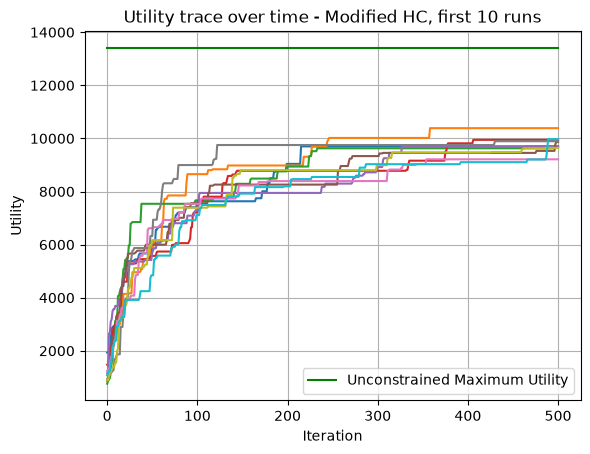

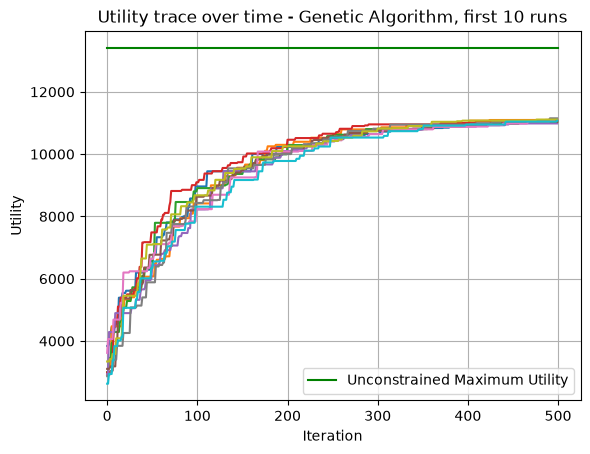

In [199]:
%matplotlib inline

unconstrained_max = sum(get_utilities(workload_90))

for trace in traces_hc[0:10]:
    plt.plot(trace)

plt.plot([unconstrained_max] * (PART_2_ITERATIONS + 1), color="green", label="Unconstrained Maximum Utility")

plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.title("Utility trace over time - Modified HC, first 10 runs")
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


for trace in traces_ga[0:10]:
    plt.plot(trace)
    
plt.plot([unconstrained_max] * (PART_2_ITERATIONS + 1), color="green", label="Unconstrained Maximum Utility")

plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.title("Utility trace over time - Genetic Algorithm, first 10 runs")
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

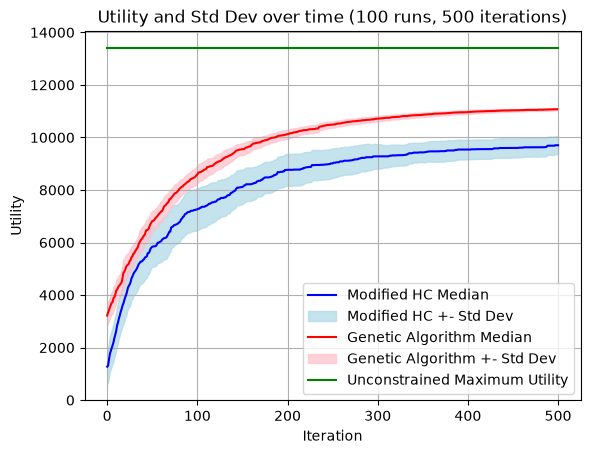

In [200]:
%matplotlib inline

hc_median = np.median(traces_hc, axis=0)
ga_median = np.median(traces_ga, axis=0)

hc_std = np.std(traces_hc, axis=0)
ga_std = np.std(traces_ga, axis=0)


plt.plot(hc_median, color="blue", label="Modified HC Median")
plt.fill_between(range(PART_2_ITERATIONS + 1), hc_median - hc_std, hc_median + hc_std, color="lightblue", alpha=0.7, label="Modified HC +- Std Dev")

plt.plot(ga_median, color="red", label="Genetic Algorithm Median")
plt.fill_between(range(PART_2_ITERATIONS), ga_median - ga_std, ga_median + ga_std, color="pink", alpha=0.7, label="Genetic Algorithm +- Std Dev")

unconstrained_max = sum(get_utilities(workload_90))
plt.plot([unconstrained_max] * (PART_2_ITERATIONS + 1), color="green", label="Unconstrained Maximum Utility")

plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.title(f"Utility and Std Dev over time ({PART_2_RUNS} runs, {PART_2_ITERATIONS} iterations)")
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

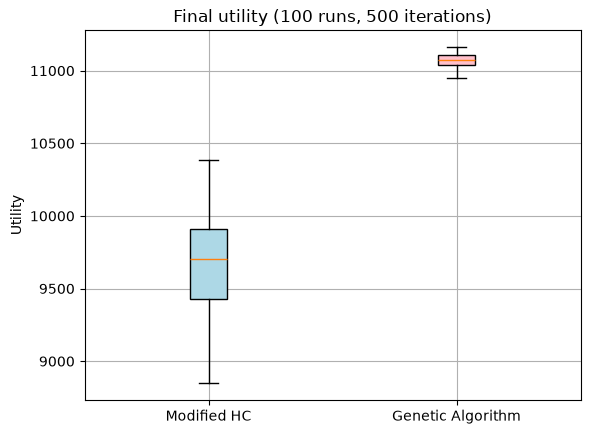

In [201]:
%matplotlib inline

bplot = plt.boxplot([best_hc, best_ga], patch_artist=True, tick_labels=['Modified HC', 'Genetic Algorithm'])
for patch, colour in zip(bplot["boxes"], ["lightblue", "pink"]):
    patch.set_facecolor(colour)

plt.title(f"Final utility ({PART_2_RUNS} runs, {PART_2_ITERATIONS} iterations)")
plt.ylabel("Utility")
plt.grid(True)
plt.show()

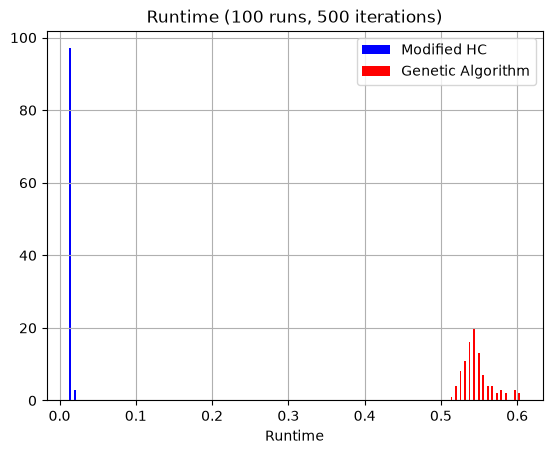

In [204]:
%matplotlib inline

plt.hist([times_hc, times_ga], 100, histtype="bar", label=["Modified HC", "Genetic Algorithm"], color=["blue", "red"])

plt.title(f"Runtime ({PART_2_RUNS} runs, {PART_2_ITERATIONS} iterations)")
plt.xlabel("Runtime")
plt.legend(loc="upper right")
plt.grid(True)
plt.show()

In [203]:
print("Modified HC:")
hc_median_runtime = np.median(times_hc)
hc_median_std = np.std(times_hc)
print(f"\tMedian utility = {hc_median[-1]}")
print(f"\tStd Dev utility = {hc_std[-1]:.3f}")
print(f"\tBest utility = {max([run[1][1] for run in runs_hc])}")
print(f"\tWorst utility = {min([run[1][1] for run in runs_hc])}")
print()
print(f"\tMedian runtime = {hc_median_runtime*1000:.3f}ms")
print(f"\tStd Dev runtime = {hc_median_std*1000:.3f}ms")
print(f"\tBest runtime = {min(times_hc)*1000:.3f}ms")
print(f"\tWorst runtime = {max(times_hc)*1000:.3f}ms")

print("Genetic Algorithm:")
ga_median_runtime = np.median(times_ga)
ga_median_std = np.std(times_ga)
print(f"\tMedian utility = {ga_median[-1]}")
print(f"\tStd Dev utility = {ga_std[-1]:.3f}")
print(f"\tBest utility = {max([run[1][1] for run in runs_ga])}")
print(f"\tWorst utility = {min([run[1][1] for run in runs_ga])}")
print()
print(f"\tMedian runtime = {ga_median_runtime*1000:.3f}ms")
print(f"\tStd Dev runtime = {ga_median_std*1000:.3f}ms")
print(f"\tBest runtime = {min(times_ga)*1000:.3f}ms")
print(f"\tWorst runtime = {max(times_ga)*1000:.3f}ms")

Modified HC:
	Median utility = 9703.5
	Std Dev utility = 344.161
	Best utility = 10386.0
	Worst utility = 8849.0

	Median runtime = 14.935ms
	Std Dev runtime = 1.442ms
	Best runtime = 12.182ms
	Worst runtime = 18.825ms
Genetic Algorithm:
	Median utility = 11074.0
	Std Dev utility = 44.038
	Best utility = 11162.0
	Worst utility = 10947.0

	Median runtime = 542.695ms
	Std Dev runtime = 18.948ms
	Best runtime = 512.547ms
	Worst runtime = 604.500ms


## Write-up
Raw trace plots show that the genetic algorithm takes a significant number (400+) of iterations to finish iterating on a solution, compared to the modified hillclimber which starts to converge as early as 200 iterations on this problem set. As well as taking more iterations, the time per iteration is also significantly higher in the genetic algorithm than in the hillclimber (median of 542ms vs. ~15ms for 500 iterations each), though the runtime standard deviation is proportionally lower for the genetic algorithm (~3.5% of the median vs ~9.6%). The runtime histogram also shows this difference in compute efficiency, with almost all hillclimber data bunched around t=0 when plotted alongside genetic algorithm runtime data, with a wide, visible gap between the distributions.

In contrast to its poor compute efficiency, the genetic algorithm has clear task performance gains. The GA achieves ~82.5% of the unconstrained maximum performance, while the hillclimber only achieves 72.3%, when comparing median performances. The GA is also remarkably consistent - the standard deviation for utility is *~7.8X* smaller than seen with the hillclimber. The gaps between best and worst performances (215.0 vs. 1537.0, GA vs hillclimber) also supports this claim of consistency.

The utility box plot also shows that the GA has a much smaller variance in performance compared to the modified hillclimber, and is a clear improvement on this problem set. There is no horizontal overlap between the plots' whiskers - the worst performance of the GA is strictly better than the best performance of the hillclimber. Statistical testing is not necessary due to the strength of the result.

# Part 3: Empirical Study and Hypothesis Testing